## 1. Project Overview
This notebook benchmarks Graph Neural Network (GNN) architectures—specifically Optimized GCN and AttentiveFP—on the ESOL (Delaney) solubility dataset. Beyond standard metrics, we employ a 'Meta-Analysis' framework to diagnose structural drivers of model failure using scaffold splitting.

### Key Experimental Setup
* Dataset: ESOL (n=1,128 molecules).
* Splitting: 80/10/10 Scaffold Split (Bemis-Murcko) to test out-of-distribution generalization.
* Features: Hybrid approach combining graph topology with global descriptors (LogP, MW, TPSA, HBD, HBA).

## 2. Methodology: Model Architectures & Data Pipeline
To maintain modularity, we refactor our GNN architectures into a `models.py` file. This includes our baseline GCN, the state-of-the-art AttentiveFP, and a Hybrid GAT model that integrates RDKit descriptors directly into the latent vector.

In [ ]:
%%writefile models.py
import torch
import torch.nn.functional as F
from torch_geometric.nn import GCNConv, global_mean_pool, BatchNorm, GATConv, AttentiveFP
from rdkit import Chem
from rdkit.Chem import Descriptors
from torch_geometric.data import Data # Import base Data class

# --- Custom Data Class for Hybrid Model ---
# This is needed if you plan to use pre-computed global features
class MyData(Data):
    def __init__(self, x=None, edge_index=None, y=None, smiles=None, global_feats=None, **kwargs):
        super().__init__(x=x, edge_index=edge_index, y=y, smiles=smiles, **kwargs)
        self.global_feats = global_feats

# --- Optimized GCN Model (for consistency, uses same class name, but different training) ---
# The optimized GCN uses the same architecture as the baseline, but with different training parameters
# and an additional dropout layer. We'll include the dropout in this definition.
class OptimizedGraphConvModel(torch.nn.Module):
    def __init__(self, num_node_features):
        super().__init__()
        self.conv1 = GCNConv(num_node_features, 64)
        self.conv2 = GCNConv(64, 64)
        self.lin = torch.nn.Linear(64, 1)

    def forward(self, x, edge_index, batch):
        x = self.conv1(x.float(), edge_index).relu()
        x = self.conv2(x, edge_index).relu()
        x = global_mean_pool(x, batch)
        x = F.dropout(x, p=0.3, training=self.training) # Added dropout
        return self.lin(x)


# --- AttentiveFP Model ---
class AttentiveFPSolubilityModel(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, num_layers=2, num_timesteps=4, dropout=0.2):
        super().__init__()
        self.attentive_fp = AttentiveFP(in_channels, hidden_channels, out_channels,
                                      edge_dim=1,
                                      num_layers=num_layers,
                                      num_timesteps=num_timesteps,
                                      dropout=dropout)

    def forward(self, x, edge_index, batch):
        num_edges = edge_index.size(1);
        dummy_edge_attr = torch.zeros((num_edges, 1), dtype=torch.float32, device=x.device)
        return self.attentive_fp(x.float(), edge_index, edge_attr=dummy_edge_attr, batch=batch)

# --- Hybrid GAT Model ---
class FastHybridModel(torch.nn.Module):
    def __init__(self, num_node_features, num_global_features=5):
        super().__init__()
        self.conv1 = GATConv(num_node_features, 32, heads=4, dropout=0.1)
        self.bn1 = BatchNorm(128)
        self.conv2 = GATConv(128, 64, heads=1, concat=False, dropout=0.1)
        self.bn2 = BatchNorm(64)
        self.lin1 = torch.nn.Linear(64 + num_global_features, 32)
        self.lin2 = torch.nn.Linear(32, 1)

    def forward(self, x, edge_index, batch, global_feats):
        x_graph = self.conv1(x.float(), edge_index)
        x_graph = self.bn1(x_graph)
        x_graph = F.elu(x_graph)

        x_graph = self.conv2(x_graph, edge_index)
        x_graph = self.bn2(x_graph)
        x_graph = F.elu(x_graph)

        x_graph = global_mean_pool(x_graph, batch)
        x_combined = torch.cat([x_graph, global_feats], dim=1)

        x_combined = F.elu(self.lin1(x_combined))
        x_combined = F.dropout(x_combined, p=0.2, training=self.training)
        return self.lin2(x_combined)

Overwriting models.py


Now that we've saved the model definitions to `models.py`, you can import them into your notebook as follows:

In [ ]:
from models import OptimizedGraphConvModel, AttentiveFPSolubilityModel, MyData

# instantiating the models from the imported classes.



# For the Optimized GCN:
# model = OptimizedGraphConvModel(dataset[0].x.shape[1])

# For the AttentiveFP:
# model_attentivefp = AttentiveFPSolubilityModel(in_channels=num_node_features, hidden_channels=64, out_channels=1)

# For the Hybrid GAT:
# model = FastHybridModel(num_node_features=dataset[0].x.shape[1], num_global_features=5)


In [ ]:
!pip install torch-geometric
!pip install rdkit

### Setting Random Seeds for Reproducibility

To ensure that our experiments are reproducible and that we get consistent results across multiple runs, it's crucial to set random seeds for all components that involve randomness. This includes Python's built-in `random` module, NumPy, and PyTorch (for CPU and GPU operations). While perfect reproducibility can sometimes be challenging, especially with complex GPU operations, seeding significantly helps in achieving consistent outcomes.

In [ ]:
import random
import numpy as np
import torch

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True # For cuDNN backend
        torch.backends.cudnn.benchmark = False # For cuDNN backend

# Set a consistent seed for reproducibility
SEED = 42
set_all_seeds(SEED)
print(f"All random seeds set to {SEED} for reproducibility.")

All random seeds set to 42 for reproducibility.


In [ ]:
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem, Lipinski

def get_structural_features(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    return {
        'ring_count':        rdMolDescriptors.CalcNumRings(mol),
        'aromatic_rings':    rdMolDescriptors.CalcNumAromaticRings(mol),
        'heteroatom_count':  rdMolDescriptors.CalcNumHeteroatoms(mol),
        'rotatable_bonds':   rdMolDescriptors.CalcNumRotatableBonds(mol),
        'mol_weight':        Descriptors.MolWt(mol),
        'logp':              Descriptors.MolLogP(mol),
        'tpsa':              rdMolDescriptors.CalcTPSA(mol),
        'hbd':               Lipinski.NumHDonors(mol),
        'hba':               Lipinski.NumHAcceptors(mol),
    }

In [ ]:
from rdkit.Chem import DataStructs
from rdkit.Chem import AllChem

def tanimoto_nn_distance(test_smiles, train_smiles_list):
    """Calculates the Tanimoto Nearest Neighbor distance for a test SMILES against a list of training SMILES.

    Args:
        test_smiles (str): SMILES string of the molecule to test.
        train_smiles_list (list): List of SMILES strings for the training set.

    Returns:
        float: 1 - max_similarity, representing the Tanimoto NN distance.
               0=identical to train, 1=completely novel.
    """
    test_mol = Chem.MolFromSmiles(test_smiles)
    if test_mol is None:
        return float('nan') # Return NaN for invalid SMILES
    test_fp = AllChem.GetMorganFingerprintAsBitVect(test_mol, 2, 2048)

    max_sim = 0
    for train_smi in train_smiles_list:
        train_mol = Chem.MolFromSmiles(train_smi)
        if train_mol is None:
            continue # Skip invalid SMILES in the training list
        train_fp = AllChem.GetMorganFingerprintAsBitVect(train_mol, 2, 2048)
        sim = DataStructs.TanimotoSimilarity(test_fp, train_fp)
        max_sim = max(max_sim, sim)

    return 1 - max_sim

### GCN Model with Optimizations

To improve upon the baseline GCN, we introduced several optimizations:

*   **Lower Learning Rate**: Reduced the learning rate from `0.01` to `0.001` to promote more stable convergence.
*   **Increased Epochs**: Extended the training duration from 50 to 150 epochs to allow the model sufficient time to learn.
*   **Dataset Split**: The dataset is now split into 80% for training, 10% for validation, and 10% for testing using **scaffold splitting**.
*   **Corrected RMSE Calculation**: Ensured the RMSE calculation accurately reflected the overall test set performance.

**Outcome**: Despite these optimizations, the simple GCN architecture still had limitations, achieving a best test RMSE of approximately **1.1477**. This suggested that a more sophisticated graph neural network approach was needed.

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from models import OptimizedGraphConvModel, MyData
import deepchem as dc

# Load ESOL dataset using load_delaney with scaffold splitting built-in
print("Loading ESOL dataset with built-in ScaffoldSplitter (80/10/10 split)... ")
_, (train_dc, val_dc, test_dc), _ = dc.molnet.load_delaney(
    featurizer='Raw',
    splitter='scaffold',
    frac_train=0.8,
    frac_valid=0.1,
    frac_test=0.1
)

# Convert DeepChem datasets to PyG MyData objects using the helper function
print("Converting datasets to PyG MyData objects...")
train_dataset_list = deepchem_dataset_to_mydata_list(train_dc)
val_dataset_list = deepchem_dataset_to_mydata_list(val_dc)
test_dataset_list = deepchem_dataset_to_mydata_list(test_dc)

# Create DataLoaders
train_loader_optimized_gcn = DataLoader(train_dataset_list, batch_size=32, shuffle=True)
val_loader_optimized_gcn = DataLoader(val_dataset_list, batch_size=32)
test_loader_optimized_gcn = DataLoader(test_dataset_list, batch_size=32)

# Initialize model
num_features_optimized_gcn = train_dataset_list[0].x.shape[1]
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_optimized_gcn = OptimizedGraphConvModel(num_features_optimized_gcn).to(device)
optimizer_optimized_gcn = torch.optim.Adam(model_optimized_gcn.parameters(), lr=0.001)

def train_optimized_gcn():
    model_optimized_gcn.train()
    total_loss = 0
    for data in train_loader_optimized_gcn:
        optimizer_optimized_gcn.zero_grad()
        data = data.to(device)
        out = model_optimized_gcn(data.x, data.edge_index, data.batch)
        loss = F.mse_loss(out, data.y.float())
        loss.backward()
        optimizer_optimized_gcn.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(train_loader_optimized_gcn.dataset)

def test_optimized_gcn(loader):
    model_optimized_gcn.eval()
    total_mse = 0
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            out = model_optimized_gcn(data.x, data.edge_index, data.batch)
            loss = F.mse_loss(out, data.y.float(), reduction='sum')
            total_mse += loss.item()
    return torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()

print("Starting Optimized GCN training loop with Scaffold Split...")
best_val_rmse = float('inf')
best_test_rmse_at_best_val = float('inf')

for epoch in range(1, 151):
    train_loss = train_optimized_gcn()
    if epoch % 10 == 0:
        train_rmse = test_optimized_gcn(train_loader_optimized_gcn)
        val_rmse = test_optimized_gcn(val_loader_optimized_gcn)
        test_rmse = test_optimized_gcn(test_loader_optimized_gcn)
        print(f'Epoch {epoch:03d} | Train Loss: {train_loss:.4f} | Val RMSE: {val_rmse:.4f} | Test RMSE: {test_rmse:.4f}')

        if val_rmse < best_val_rmse:
            best_val_rmse = val_rmse
            best_test_rmse_at_best_val = test_rmse

print(f"\nTraining completed. Best Validation RMSE: {best_val_rmse:.4f}")
print(f"Test RMSE at best validation epoch: {best_test_rmse_at_best_val:.4f}")

Loading ESOL dataset with built-in ScaffoldSplitter (80/10/10 split)... 
Converting datasets to PyG MyData objects...
Processing 902 molecules...


/tmp/ipykernel_674/488162523.py:59: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  mydata_list.append(MyData(x=x, edge_index=edge_index, y=torch.tensor([label], dtype=torch.float), smiles=mol_smiles, global_feats=global_feats))


  Processed 902/902 molecules. Done.
Processing 113 molecules...
  Processed 113/113 molecules. Done.
Processing 113 molecules...
  Processed 113/113 molecules. Done.
Starting Optimized GCN training loop with Scaffold Split...
Epoch 010 | Train Loss: 0.8628 | Val RMSE: 0.9485 | Test RMSE: 1.0240
Epoch 020 | Train Loss: 0.7508 | Val RMSE: 0.9210 | Test RMSE: 0.9939
Epoch 030 | Train Loss: 0.6348 | Val RMSE: 0.8324 | Test RMSE: 0.9032
Epoch 040 | Train Loss: 0.5203 | Val RMSE: 0.7582 | Test RMSE: 0.8244
Epoch 050 | Train Loss: 0.4488 | Val RMSE: 0.6890 | Test RMSE: 0.7475
Epoch 060 | Train Loss: 0.4296 | Val RMSE: 0.6432 | Test RMSE: 0.6847
Epoch 070 | Train Loss: 0.3923 | Val RMSE: 0.6295 | Test RMSE: 0.6733
Epoch 080 | Train Loss: 0.3599 | Val RMSE: 0.6447 | Test RMSE: 0.6656
Epoch 090 | Train Loss: 0.3697 | Val RMSE: 0.6297 | Test RMSE: 0.6742
Epoch 100 | Train Loss: 0.3595 | Val RMSE: 0.6333 | Test RMSE: 0.6509
Epoch 110 | Train Loss: 0.3464 | Val RMSE: 0.6365 | Test RMSE: 0.6644
Epo

### Installing DeepChem

We'll install DeepChem to leverage its powerful dataset loading and splitting functionalities, especially for scaffold splitting, which is crucial for molecular datasets.

In [ ]:
!pip install deepchem

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 552.4/552.4 kB 17.7 MB/s eta 0:00:00


### DeepChem Dataset Preparation Helper

To seamlessly integrate DeepChem's dataset handling with our existing PyTorch Geometric and `MyData` structure, we'll create a helper function. This function will convert `deepchem.data.DiskDataset` objects into a list of `MyData` objects, pre-computing RDKit descriptors for each molecule, similar to what we did for the optimized hybrid model.

In [ ]:
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import Descriptors
import torch
from models import MyData

def deepchem_dataset_to_mydata_list(dc_dataset):
    """Converts a deepchem.data.DiskDataset to a list of MyData objects with RDKit descriptors."""
    mydata_list = []
    print(f"Processing {len(dc_dataset)} molecules...")
    for i, (mol_smiles, label) in enumerate(zip(dc_dataset.ids, dc_dataset.y)):
        if i % 100 == 0:
            print(f"  Processed {i}/{len(dc_dataset)} molecules.", end='\r')

        mol = Chem.MolFromSmiles(mol_smiles)
        if mol is None:
            # Skip invalid SMILES
            continue

        # Generate node features (same logic as mol_to_pyg_data helper from previous cells)
        atom_features_list = []
        for atom in mol.GetAtoms():
            features = [
                atom.GetAtomicNum(),
                atom.GetDegree(),
                atom.GetFormalCharge(),
                int(atom.GetChiralTag()),
                atom.GetTotalNumHs(),
                int(atom.GetHybridization()),
                int(atom.GetIsAromatic()),
                atom.GetNumRadicalElectrons(),
                int(atom.IsInRing()),
            ]
            atom_features_list.append(features)
        x = torch.tensor(atom_features_list, dtype=torch.float).view(-1, 9)

        # Get edge_index (bond connectivity)
        edge_indices = []
        for bond in mol.GetBonds():
            i = bond.GetBeginAtomIdx()
            j = bond.GetEndAtomIdx()
            edge_indices.append([i, j])
            edge_indices.append([j, i]) # Add reverse direction for undirected graph

        if not edge_indices:
            edge_index = torch.empty((2, 0), dtype=torch.long)
        else:
            edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

        # Pre-compute RDKit global descriptors
        logp = Descriptors.MolLogP(mol)
        mol_wt = Descriptors.MolWt(mol) / 100.0
        tpsa = Descriptors.TPSA(mol) / 100.0
        hbd = float(Descriptors.NumHDonors(mol))
        hba = float(Descriptors.NumHAcceptors(mol))
        global_feats = torch.tensor([[logp, mol_wt, tpsa, hbd, hba]], dtype=torch.float32)

        # Create MyData object
        mydata_list.append(MyData(x=x, edge_index=edge_index, y=torch.tensor([label], dtype=torch.float), smiles=mol_smiles, global_feats=global_feats))
    print(f"  Processed {len(dc_dataset)}/{len(dc_dataset)} molecules. Done.")
    return mydata_list

### AttentiveFP Model for ESOL Solubility Prediction

Now, let's implement and train an AttentiveFP model. AttentiveFP is a powerful graph neural network that uses graph attention mechanisms over multiple message-passing steps to learn molecular representations. It's particularly well-suited for molecular property prediction tasks.

In [ ]:
import torch
import torch.nn.functional as F
from torch_geometric.loader import DataLoader
from torch_geometric.nn import AttentiveFP, global_mean_pool
import deepchem as dc
from models import AttentiveFPSolubilityModel # Import AttentiveFP Model from models.py

# 1. Load ESOL dataset with built-in ScaffoldSplitter (80/10/10 split)
print("Loading ESOL dataset with built-in ScaffoldSplitter for AttentiveFP...")
_, (train_dc_afp, val_dc_afp, test_dc_afp), _ = dc.molnet.load_delaney(
    featurizer='Raw',
    splitter='scaffold',
    frac_train=0.8,
    frac_valid=0.1,
    frac_test=0.1
)

# 2. Convert DeepChem datasets to PyG MyData objects using the helper function
print("Converting datasets to PyG MyData objects...")
train_dataset_afp_list = deepchem_dataset_to_mydata_list(train_dc_afp)
val_dataset_afp_list = deepchem_dataset_to_mydata_list(val_dc_afp)
test_dataset_afp_list = deepchem_dataset_to_mydata_list(test_dc_afp)

# 3. Create DataLoaders
train_loader_attentivefp = DataLoader(train_dataset_afp_list, batch_size=32, shuffle=True)
val_loader_attentivefp = DataLoader(val_dataset_afp_list, batch_size=32)
test_loader_attentivefp = DataLoader(test_dataset_afp_list, batch_size=32)

# Determine input features from the dataset
num_node_features_attentivefp = train_dataset_afp_list[0].x.shape[1]

# Initialize the model, optimizer, and scheduler
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_attentivefp = AttentiveFPSolubilityModel(
    in_channels=num_node_features_attentivefp,
    hidden_channels=64,
    out_channels=1, # Single output for regression
    num_layers=2,
    num_timesteps=4
).to(device)

optimizer_attentivefp = torch.optim.Adam(model_attentivefp.parameters(), lr=0.0005, weight_decay=1e-4)
scheduler_attentivefp = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_attentivefp, mode='min', factor=0.5, patience=10)

print(f"AttentiveFP Model initialized on {device} with Scaffold Split data.")

Loading ESOL dataset with built-in ScaffoldSplitter for AttentiveFP...
Converting datasets to PyG MyData objects...
Processing 902 molecules...
  Processed 902/902 molecules. Done.
Processing 113 molecules...
  Processed 113/113 molecules. Done.
Processing 113 molecules...
  Processed 113/113 molecules. Done.
AttentiveFP Model initialized on cpu with Scaffold Split data.


In [ ]:
# Training function for AttentiveFP
def train_attentivefp():
    model_attentivefp.train()
    total_loss = 0
    for data in train_loader_attentivefp:
        optimizer_attentivefp.zero_grad()
        data = data.to(device)
        out = model_attentivefp(data.x, data.edge_index, data.batch)
        loss = F.mse_loss(out, data.y.float())
        loss.backward()
        optimizer_attentivefp.step()
        total_loss += loss.item() * data.num_graphs
    return total_loss / len(train_loader_attentivefp.dataset)

# Testing function for AttentiveFP
def test_attentivefp(loader):
    model_attentivefp.eval()
    total_mse = 0
    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            out = model_attentivefp(data.x, data.edge_index, data.batch)
            loss = F.mse_loss(out, data.y.float(), reduction='sum')
            total_mse += loss.item()
    return torch.sqrt(torch.tensor(total_mse / len(loader.dataset))).item()

# Training loop
best_val_rmse_afp = float('inf')
best_test_rmse_at_best_val_afp = float('inf')

print("Starting AttentiveFP training loop with Scaffold Split...")

for epoch in range(1, 151):
    train_loss = train_attentivefp()
    if epoch % 10 == 0:
        train_rmse = test_attentivefp(train_loader_attentivefp)
        val_rmse = test_attentivefp(val_loader_attentivefp)
        test_rmse = test_attentivefp(test_loader_attentivefp)

        scheduler_attentivefp.step(val_rmse)

        if val_rmse < best_val_rmse_afp:
            best_val_rmse_afp = val_rmse
            best_test_rmse_at_best_val_afp = test_rmse
            torch.save(model_attentivefp.state_dict(), 'best_attentivefp_model.pt')

        print(f'Epoch {epoch:03d} | Train Loss: {train_loss:.4f} | Val RMSE: {val_rmse:.4f} | Test RMSE: {test_rmse:.4f} | Best Val RMSE: {best_val_rmse_afp:.4f}')

print(f"\nAttentiveFP training completed!")
print(f"Best Validation RMSE: {best_val_rmse_afp:.4f}")
print(f"Test RMSE at best validation epoch: {best_test_rmse_at_best_val_afp:.4f}")

Starting AttentiveFP training loop with Scaffold Split...
Epoch 010 | Train Loss: 0.3639 | Val RMSE: 0.6926 | Test RMSE: 0.7559 | Best Val RMSE: 0.6926
Epoch 020 | Train Loss: 0.2469 | Val RMSE: 0.6105 | Test RMSE: 0.6232 | Best Val RMSE: 0.6105
Epoch 030 | Train Loss: 0.1620 | Val RMSE: 0.6032 | Test RMSE: 0.5875 | Best Val RMSE: 0.6032
Epoch 040 | Train Loss: 0.1353 | Val RMSE: 0.4917 | Test RMSE: 0.4863 | Best Val RMSE: 0.4917
Epoch 050 | Train Loss: 0.1208 | Val RMSE: 0.5025 | Test RMSE: 0.4730 | Best Val RMSE: 0.4917
Epoch 060 | Train Loss: 0.1029 | Val RMSE: 0.4827 | Test RMSE: 0.4852 | Best Val RMSE: 0.4827
Epoch 070 | Train Loss: 0.0928 | Val RMSE: 0.5017 | Test RMSE: 0.4517 | Best Val RMSE: 0.4827
Epoch 080 | Train Loss: 0.0905 | Val RMSE: 0.4856 | Test RMSE: 0.4818 | Best Val RMSE: 0.4827
Epoch 090 | Train Loss: 0.0925 | Val RMSE: 0.4791 | Test RMSE: 0.4560 | Best Val RMSE: 0.4791
Epoch 100 | Train Loss: 0.0779 | Val RMSE: 0.4611 | Test RMSE: 0.4542 | Best Val RMSE: 0.4611
Ep

### Generating Error Tables for GCN and AttentiveFP

We will now define specialized evaluation functions to collect per-molecule predictions and compare them against actual values. This will help us identify which specific molecular structures are most challenging for our models.

In [ ]:
import pandas as pd
import torch
import torch.nn.functional as F
from rdkit import RDLogger

# Suppress RDKit deprecation warnings for cleaner output
lg = RDLogger.logger()
lg.setLevel(RDLogger.CRITICAL)

def get_predictions(model, loader, device):
    model.eval()
    all_y = []
    all_out = []
    all_smiles = []

    with torch.no_grad():
        for data in loader:
            data = data.to(device)
            out = model(data.x, data.edge_index, data.batch)

            all_y.extend(data.y.cpu().numpy().flatten().tolist())
            all_out.extend(out.cpu().numpy().flatten().tolist())
            all_smiles.extend(data.smiles)

    return all_smiles, all_y, all_out

# Prepare training SMILES for Tanimoto distance calculations
train_smiles_gcn = [data.smiles for data in train_dataset_list]
train_smiles_afp = [data.smiles for data in train_dataset_afp_list]

# --- GCN Error Table ---
print("Collecting predictions and calculating features for Optimized GCN (Scaffold Split)... ")
gcn_smiles, gcn_true, gcn_pred = get_predictions(model_optimized_gcn, test_loader_optimized_gcn, device)

gcn_error_df = pd.DataFrame({
    'smiles': gcn_smiles,
    'true_value': gcn_true,
    'predicted_value': gcn_pred
})
gcn_error_df['error'] = (gcn_error_df['predicted_value'] - gcn_error_df['true_value']).abs()

# Append structural features
features_gcn = pd.DataFrame(gcn_error_df['smiles'].apply(get_structural_features).tolist())
gcn_error_df = pd.concat([gcn_error_df, features_gcn], axis=1)

# Append Tanimoto distance
gcn_error_df['tanimoto_nn_distance'] = gcn_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_gcn))

print("Optimized GCN Enriched Error Table (First 5 rows):")
display(gcn_error_df.head())

# --- AttentiveFP Error Table ---
print("\nCollecting predictions and calculating features for AttentiveFP (Scaffold Split)... ")
afp_smiles, afp_true, afp_pred = get_predictions(model_attentivefp, test_loader_attentivefp, device)

afp_error_df = pd.DataFrame({
    'smiles': afp_smiles,
    'true_value': afp_true,
    'predicted_value': afp_pred
})
afp_error_df['error'] = (afp_error_df['predicted_value'] - afp_error_df['true_value']).abs()

# Append structural features
features_afp = pd.DataFrame(afp_error_df['smiles'].apply(get_structural_features).tolist())
afp_error_df = pd.concat([afp_error_df, features_afp], axis=1)

# Append Tanimoto distance
afp_error_df['tanimoto_nn_distance'] = afp_error_df['smiles'].apply(lambda x: tanimoto_nn_distance(x, train_smiles_afp))

print("AttentiveFP Enriched Error Table (First 5 rows):")
display(afp_error_df.head())

Optimized GCN Enriched Error Table (First 5 rows):


,smiles,true_value,predicted_value,error,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,c1cc2ccc3cccc4ccc(c1)c2c34,-1.601145,-1.962554,0.361409,4,4,0,0,202.256,4.58400,0.00,0,0,0.538462
1,Cc1cc(=O)[nH]c(=S)[nH]1,0.208483,0.125574,0.082909,1,1,4,0,142.183,0.74091,48.65,2,2,0.741935
2,Oc1ccc(cc1)C2(OC(=O)c3ccccc23)c4ccc(O)cc4,-0.016027,-0.953659,0.937632,4,3,4,2,318.328,3.56010,66.76,2,4,0.696970
3,c1ccc2c(c1)cc3ccc4cccc5ccc2c3c45,-2.821917,-2.313506,0.508411,5,5,0,0,252.316,5.73720,0.00,0,0,0.466667
4,C1=Cc2cccc3cccc1c23,-0.528916,-1.148828,0.619912,3,2,0,0,152.196,3.32360,0.00,0,0,0.647059



AttentiveFP Enriched Error Table (First 5 rows):


,smiles,true_value,predicted_value,error,ring_count,aromatic_rings,heteroatom_count,rotatable_bonds,mol_weight,logp,tpsa,hbd,hba,tanimoto_nn_distance
0,c1cc2ccc3cccc4ccc(c1)c2c34,-1.601145,-1.964935,0.363790,4,4,0,0,202.256,4.58400,0.00,0,0,0.538462
1,Cc1cc(=O)[nH]c(=S)[nH]1,0.208483,0.420639,0.212156,1,1,4,0,142.183,0.74091,48.65,2,2,0.741935
2,Oc1ccc(cc1)C2(OC(=O)c3ccccc23)c4ccc(O)cc4,-0.016027,-1.383217,1.367190,4,3,4,2,318.328,3.56010,66.76,2,4,0.696970
3,c1ccc2c(c1)cc3ccc4cccc5ccc2c3c45,-2.821917,-2.496961,0.324956,5,5,0,0,252.316,5.73720,0.00,0,0,0.466667
4,C1=Cc2cccc3cccc1c23,-0.528916,-0.933878,0.404962,3,2,0,0,152.196,3.32360,0.00,0,0,0.647059


## 4. GitHub Clean-up Checklist
Before pushing to GitHub, consider these steps for a professional repository:
1. Requirement Management: Include a requirements.txt containing torch-geometric, rdkit, deepchem, and statsmodels.
2. Modularization: Ensure models.py is included in the root directory.
3. Visualization: Clear all long stack traces or installation logs (like the pip install outputs) for readability.
4. License Selection: For an independent project like yours, the MIT License is highly recommended. It is a 'permissive' license that allows anyone to use, modify, and distribute your code, provided they include the original copyright notice. This is ideal for maximizing the impact of your research while protecting yourself from liability.

In [ ]:
# Save the GCN scaffold split error DataFrame to CSV
gcn_error_df.to_csv('gcn_scaffold_predictions.csv', index=False)
print("Saved 'gcn_scaffold_predictions.csv'")

# Save the AttentiveFP scaffold split error DataFrame to CSV
afp_error_df.to_csv('afp_scaffold_predictions.csv', index=False)
print("Saved 'afp_scaffold_predictions.csv'")

print("\nYou can now download these files from the Colab file browser.")

Saved 'gcn_scaffold_predictions.csv'
Saved 'afp_scaffold_predictions.csv'

You can now download these files from the Colab file browser.


### Comparative Error Analysis (Scaffold Split)

We will now compare the error profiles of the **Optimized GCN** and **AttentiveFP** models on the scaffold test set. This helps determine which architecture generalizes better to novel chemical structures.

In [ ]:
import numpy as np

# Calculate basic MAE comparison
mae_gcn = gcn_error_df['error'].mean()
mae_afp = afp_error_df['error'].mean()

print(f"--- Scaffold Split MAE Comparison ---")
print(f"Optimized GCN MAE:  {mae_gcn:.4f}")
print(f"AttentiveFP MAE:    {mae_afp:.4f}")

# Identify the most difficult molecule for the best model (AttentiveFP)
worst_mol_afp = afp_error_df.loc[afp_error_df['error'].idxmax()]
print(f"\nWorst AttentiveFP Prediction (SMILES): {worst_mol_afp['smiles']}")
print(f"True: {worst_mol_afp['true_value']:.4f}, Pred: {worst_mol_afp['predicted_value']:.4f}, Error: {worst_mol_afp['error']:.4f}")

--- Scaffold Split MAE Comparison ---
Optimized GCN MAE:  0.4751
AttentiveFP MAE:    0.4063

Worst AttentiveFP Prediction (SMILES): ClC1(C(=O)C2(Cl)C3(Cl)C14Cl)C5(Cl)C2(Cl)C3(Cl)C(Cl)(Cl)C45Cl
True: -1.1574, Pred: -3.0339, Error: 1.8765


### Correlation: Tanimoto Distance vs. Error (GCN vs. AttentiveFP)

We will now calculate the correlation between the `tanimoto_nn_distance` and the `error` for both models. This reveals if structural novelty (being far from the training set) impact the GCN and AttentiveFP differently.

In [ ]:
corr_gcn = gcn_error_df['tanimoto_nn_distance'].corr(gcn_error_df['error'])
print(f"Correlation (Tanimoto NN vs Error) - Optimized GCN: {corr_gcn:.4f}")

corr_afp = afp_error_df['tanimoto_nn_distance'].corr(afp_error_df['error'])
print(f"Correlation (Tanimoto NN vs Error) - AttentiveFP: {corr_afp:.4f}")

Correlation (Tanimoto NN vs Error) - Optimized GCN: -0.1296
Correlation (Tanimoto NN vs Error) - AttentiveFP: 0.2608


### Visualizing Correlation: Tanimoto Nearest Neighbor Distance vs. Absolute Error

To further explore the relationship between structural novelty (Tanimoto NN Distance) and prediction error, we'll create scatter plots for both splits. This visual representation can complement the calculated correlation coefficients by showing the distribution and density of data points.

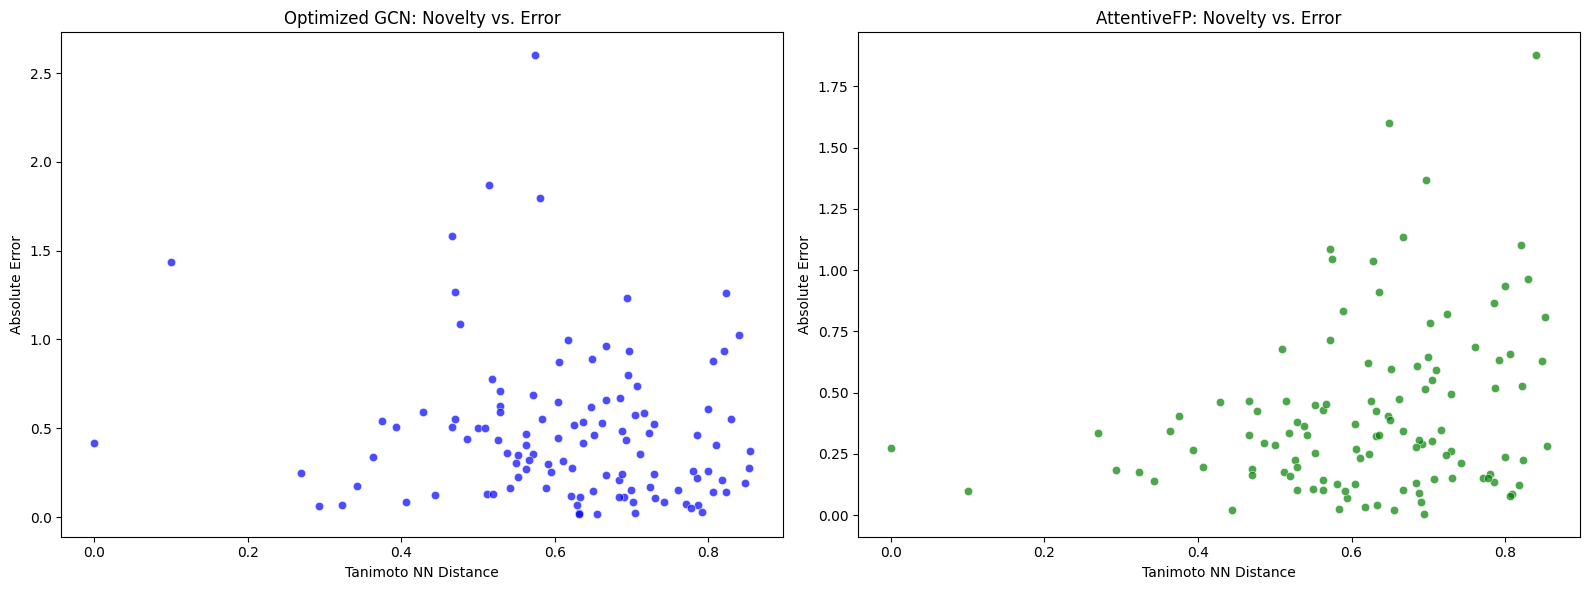

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- GCN Plot ---
sns.scatterplot(x='tanimoto_nn_distance', y='error', data=gcn_error_df, alpha=0.7, ax=ax1, color='blue')
ax1.set_title('Optimized GCN: Novelty vs. Error')
ax1.set_xlabel('Tanimoto NN Distance')
ax1.set_ylabel('Absolute Error')

# --- AttentiveFP Plot ---
sns.scatterplot(x='tanimoto_nn_distance', y='error', data=afp_error_df, alpha=0.7, ax=ax2, color='green')
ax2.set_title('AttentiveFP: Novelty vs. Error')
ax2.set_xlabel('Tanimoto NN Distance')
ax2.set_ylabel('Absolute Error')

plt.tight_layout()
plt.show()

### Regression Analysis: Novelty as a Predictor of Error

We will perform linear regression to quantify how much of the prediction error in each model can be explained by structural novelty (Tanimoto NN Distance).

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

def run_novelty_regression(df, model_name):
    X = df[['tanimoto_nn_distance']]
    y = df['error']
    reg = LinearRegression().fit(X, y)
    r2 = r2_score(y, reg.predict(X))
    print(f"--- {model_name} Novelty Regression ---")
    print(f"Coefficient: {reg.coef_[0]:.4f}, R-squared: {r2:.4f}\n")

run_novelty_regression(gcn_error_df, "Optimized GCN")
run_novelty_regression(afp_error_df, "AttentiveFP")

--- Optimized GCN Novelty Regression ---
Coefficient: -0.3623, R-squared: 0.0168

--- AttentiveFP Novelty Regression ---
Coefficient: 0.5810, R-squared: 0.0680



### Structural Feature Distributions (GCN vs. AFP sets)

We check the descriptive statistics of the test set features to ensure consistency between the evaluation sets for both models.

In [ ]:
cols = ['logp', 'mol_weight', 'tpsa', 'ring_count', 'tanimoto_nn_distance']
print("--- GCN Test Set Features ---")
display(gcn_error_df[cols].describe())

print("\n--- AttentiveFP Test Set Features ---")
display(afp_error_df[cols].describe())

--- GCN Test Set Features ---


,logp,mol_weight,tpsa,ring_count,tanimoto_nn_distance
count,113.000000,113.000000,113.000000,113.000000,113.000000
mean,2.546486,270.737398,54.236195,2.769912,0.619710
std,2.482617,100.781186,46.883027,1.210142,0.152555
min,-7.571400,58.080000,0.000000,1.000000,0.000000
25%,1.171600,212.252000,25.780000,2.000000,0.538462
50%,2.669100,261.064000,43.370000,3.000000,0.632653
75%,4.198300,337.463000,73.800000,3.000000,0.716667
max,7.725600,588.562000,268.680000,7.000000,0.854839



--- AttentiveFP Test Set Features ---


,logp,mol_weight,tpsa,ring_count,tanimoto_nn_distance
count,113.000000,113.000000,113.000000,113.000000,113.000000
mean,2.546486,270.737398,54.236195,2.769912,0.619710
std,2.482617,100.781186,46.883027,1.210142,0.152555
min,-7.571400,58.080000,0.000000,1.000000,0.000000
25%,1.171600,212.252000,25.780000,2.000000,0.538462
50%,2.669100,261.064000,43.370000,3.000000,0.632653
75%,4.198300,337.463000,73.800000,3.000000,0.716667
max,7.725600,588.562000,268.680000,7.000000,0.854839


### Data Integrity Check

Ensuring no NaN values were introduced during feature extraction or Tanimoto distance calculations.

In [ ]:
print("Missing values in GCN table:", gcn_error_df.isnull().sum().sum())
print("Missing values in AFP table:", afp_error_df.isnull().sum().sum())

Missing values in GCN table: 0
Missing values in AFP table: 0


The output above shows the number of NaN values in each column. If all counts are 0, it means there are no missing values in that column. If there are non-zero values, it indicates the presence of missing data.

In [ ]:
print("--- Data Info: Optimized GCN Error Table ---")
gcn_error_df.info()

print("\n--- Data Info: AttentiveFP Error Table ---")
afp_error_df.info()

--- Data Info: Optimized GCN Error Table ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   smiles                113 non-null    object 
 1   true_value            113 non-null    float64
 2   predicted_value       113 non-null    float64
 3   error                 113 non-null    float64
 4   ring_count            113 non-null    int64  
 5   aromatic_rings        113 non-null    int64  
 6   heteroatom_count      113 non-null    int64  
 7   rotatable_bonds       113 non-null    int64  
 8   mol_weight            113 non-null    float64
 9   logp                  113 non-null    float64
 10  tpsa                  113 non-null    float64
 11  hbd                   113 non-null    int64  
 12  hba                   113 non-null    int64  
 13  tanimoto_nn_distance  113 non-null    float64
dtypes: float64(7), int64(6), obje

### Summary Statistics for Absolute Error

We'll now examine the descriptive statistics for the `error` column in both the random and scaffold split DataFrames. This provides a quick numerical summary of the error distribution, including mean, standard deviation, and quartiles.

In [ ]:
print("--- Optimized GCN Error Statistics (Scaffold Split) ---")
display(gcn_error_df['error'].describe())

print("\n--- AttentiveFP Error Statistics (Scaffold Split) ---")
display(afp_error_df['error'].describe())

--- Optimized GCN Error Statistics (Scaffold Split) ---


,error
count,113.000000
mean,0.475051
std,0.426442
min,0.018291
25%,0.164328
50%,0.404614
75%,0.594343
max,2.600531



--- AttentiveFP Error Statistics (Scaffold Split) ---


,error
count,113.000000
mean,0.406264
std,0.339845
min,0.005115
25%,0.159156
50%,0.323930
75%,0.524646
max,1.876466


### Molecular Weight Influence on Error (GCN vs. AFP)

We divide molecules into 'high error' and 'low error' groups (based on the median error of each model) to see if high Molecular Weight correlates with model failure.

In [ ]:
def analyze_mw_bias(df, name):
    med = df['error'].median()
    high_err = df[df['error'] >= med]['mol_weight']
    low_err = df[df['error'] < med]['mol_weight']
    print(f"--- {name} MW Analysis ---")
    print(f"Low Error Mean MW: {low_err.mean():.2f}")
    print(f"High Error Mean MW: {high_err.mean():.2f}\n")

analyze_mw_bias(gcn_error_df, "GCN")
analyze_mw_bias(afp_error_df, "AttentiveFP")

--- GCN MW Analysis ---
Low Error Mean MW: 240.34
High Error Mean MW: 300.60

--- AttentiveFP MW Analysis ---
Low Error Mean MW: 249.65
High Error Mean MW: 291.45



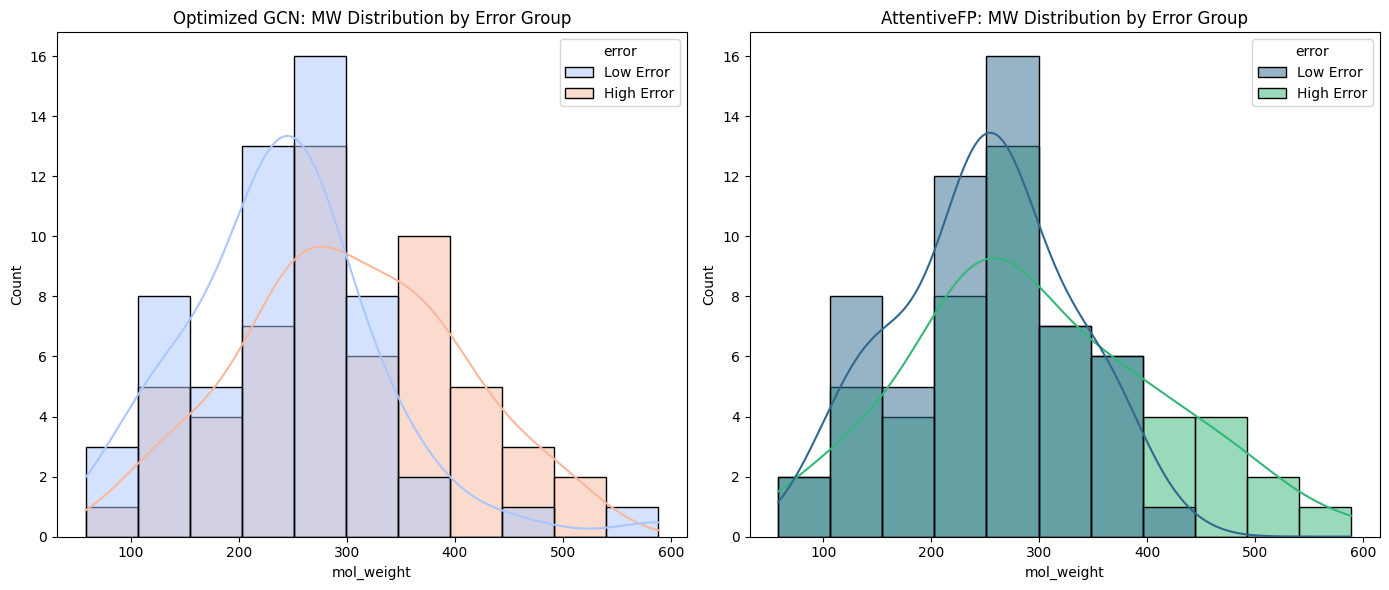

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# GCN Error vs Mol Weight Distribution
sns.histplot(gcn_error_df, x='mol_weight', hue=pd.qcut(gcn_error_df['error'], 2, labels=['Low Error', 'High Error']),
             kde=True, ax=ax1, palette='coolwarm')
ax1.set_title('Optimized GCN: MW Distribution by Error Group')

# AFP Error vs Mol Weight Distribution
sns.histplot(afp_error_df, x='mol_weight', hue=pd.qcut(afp_error_df['error'], 2, labels=['Low Error', 'High Error']),
             kde=True, ax=ax2, palette='viridis')
ax2.set_title('AttentiveFP: MW Distribution by Error Group')

plt.tight_layout()
plt.show()

### Mann-Whitney U Test: Significant Predictors of Error

We test if structural features differ significantly between high and low error groups for the **AttentiveFP** model.

In [ ]:
from scipy.stats import mannwhitneyu

med_afp = afp_error_df['error'].median()
afp_high = afp_error_df[afp_error_df['error'] >= med_afp]
afp_low = afp_error_df[afp_error_df['error'] < med_afp]

feats = ['logp', 'mol_weight', 'tpsa', 'tanimoto_nn_distance']
for f in feats:
    s, p = mannwhitneyu(afp_high[f], afp_low[f])
    print(f"AttentiveFP - {f} P-value: {p:.4f}")

AttentiveFP - logp P-value: 0.5072
AttentiveFP - mol_weight P-value: 0.0750
AttentiveFP - tpsa P-value: 0.3155
AttentiveFP - tanimoto_nn_distance P-value: 0.3261


In [ ]:
med_gcn = gcn_error_df['error'].median()
gcn_high = gcn_error_df[gcn_error_df['error'] >= med_gcn]
gcn_low = gcn_error_df[gcn_error_df['error'] < med_gcn]

print("\n--- Optimized GCN Mann-Whitney U Test ---")
for f in feats:
    s, p = mannwhitneyu(gcn_high[f], gcn_low[f])
    print(f"Optimized GCN - {f} P-value: {p:.4f}")


--- Optimized GCN Mann-Whitney U Test ---
Optimized GCN - logp P-value: 0.0004
Optimized GCN - mol_weight P-value: 0.0009
Optimized GCN - tpsa P-value: 0.3425
Optimized GCN - tanimoto_nn_distance P-value: 0.1511


### Multivariate Regression: Controlling for Novelty

We use OLS to see if chemical features predict **AttentiveFP** error even after accounting for Tanimoto distance.

In [ ]:
import statsmodels.api as sm

X = afp_error_df[['tanimoto_nn_distance', 'logp', 'mol_weight', 'tpsa', 'ring_count']]
X = sm.add_constant(X)
y = afp_error_df['error']
ols_afp = sm.OLS(y, X).fit()
print(ols_afp.summary())

                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.214
Model:                            OLS   Adj. R-squared:                  0.178
Method:                 Least Squares   F-statistic:                     5.841
Date:                Sat, 20 Jun 2026   Prob (F-statistic):           8.25e-05
Time:                        05:04:49   Log-Likelihood:                -24.245
No. Observations:                 113   AIC:                             60.49
Df Residuals:                     107   BIC:                             76.85
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.2788 

In [ ]:
print("\n--- Multivariate Regression: Optimized GCN ---")
X_gcn = sm.add_constant(gcn_error_df[['tanimoto_nn_distance', 'logp', 'mol_weight', 'tpsa', 'ring_count']])
ols_gcn = sm.OLS(gcn_error_df['error'], X_gcn).fit()
print(ols_gcn.summary())


--- Multivariate Regression: Optimized GCN ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.319
Model:                            OLS   Adj. R-squared:                  0.287
Method:                 Least Squares   F-statistic:                     10.00
Date:                Sat, 20 Jun 2026   Prob (F-statistic):           7.13e-08
Time:                        05:04:52   Log-Likelihood:                -41.861
No. Observations:                 113   AIC:                             95.72
Df Residuals:                     107   BIC:                             112.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------

### Interaction Analysis: Does Novelty Amplify Structural Predictors?

We are testing the hypothesis that structural features (like Molecular Weight) have a stronger impact on error when the molecule is structurally 'novel' (high Tanimoto Distance). We add an interaction term `mw_x_novelty` to the model. If the coefficient for this term is significant, it suggests the model's physical understanding of size/solubility breaks down as it moves further from the training distribution.

In [ ]:
afp_error_df['mw_x_novelty'] = afp_error_df['mol_weight'] * afp_error_df['tanimoto_nn_distance']
X_int = sm.add_constant(afp_error_df[['tanimoto_nn_distance', 'mol_weight', 'mw_x_novelty']])
interact_mod = sm.OLS(afp_error_df['error'], X_int).fit()
print(interact_mod.summary())

                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.214
Model:                            OLS   Adj. R-squared:                  0.193
Method:                 Least Squares   F-statistic:                     9.921
Date:                Sat, 20 Jun 2026   Prob (F-statistic):           7.74e-06
Time:                        05:04:56   Log-Likelihood:                -24.240
No. Observations:                 113   AIC:                             56.48
Df Residuals:                     109   BIC:                             67.39
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    0.7519 

In [ ]:
gcn_error_df['mw_x_novelty'] = gcn_error_df['mol_weight'] * gcn_error_df['tanimoto_nn_distance']
X_int_gcn = sm.add_constant(gcn_error_df[['tanimoto_nn_distance', 'mol_weight', 'mw_x_novelty']])
interact_mod_gcn = sm.OLS(gcn_error_df['error'], X_int_gcn).fit()
print("\n--- Interaction Analysis: Optimized GCN ---")
print(interact_mod_gcn.summary())


--- Interaction Analysis: Optimized GCN ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.198
Model:                            OLS   Adj. R-squared:                  0.176
Method:                 Least Squares   F-statistic:                     8.957
Date:                Sat, 20 Jun 2026   Prob (F-statistic):           2.35e-05
Time:                        05:04:59   Log-Likelihood:                -51.080
No. Observations:                 113   AIC:                             110.2
Df Residuals:                     109   BIC:                             121.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------

### Refined Multivariate Model (AttentiveFP)

Expanding predictors to include more specific structural counts.

In [ ]:
# Refined Features List: Specific structural counts + novelty control
refined_features = ['tanimoto_nn_distance', 'aromatic_rings', 'rotatable_bonds', 'heteroatom_count', 'logp', 'mol_weight']

# AttentiveFP Refined Model
X_ref_afp = sm.add_constant(afp_error_df[refined_features])
refined_mod_afp = sm.OLS(afp_error_df['error'], X_ref_afp).fit()

# GCN Refined Model
X_ref_gcn = sm.add_constant(gcn_error_df[refined_features])
refined_mod_gcn = sm.OLS(gcn_error_df['error'], X_ref_gcn).fit()

print("--- Refined OLS Result: AttentiveFP ---")
print(refined_mod_afp.summary())
print("\n--- Refined OLS Result: Optimized GCN ---")
print(refined_mod_gcn.summary())

--- Refined OLS Result: AttentiveFP ---
                            OLS Regression Results                            
Dep. Variable:                  error   R-squared:                       0.213
Model:                            OLS   Adj. R-squared:                  0.169
Method:                 Least Squares   F-statistic:                     4.788
Date:                Sat, 20 Jun 2026   Prob (F-statistic):           0.000234
Time:                        05:05:05   Log-Likelihood:                -24.331
No. Observations:                 113   AIC:                             62.66
Df Residuals:                     106   BIC:                             81.75
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------

### VIF Diagnostics

Checking for multicollinearity in our error-prediction features.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

def check_vif(df, label):
    X = sm.add_constant(df[['tanimoto_nn_distance', 'aromatic_rings', 'rotatable_bonds', 'heteroatom_count', 'logp', 'mol_weight']])
    vif = pd.DataFrame()
    vif["feature"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]
    print(f"--- VIF Diagnostics: {label} ---")
    display(vif.sort_values("VIF", ascending=False))

check_vif(gcn_error_df, "Optimized GCN")
check_vif(afp_error_df, "AttentiveFP")

--- VIF Diagnostics: Optimized GCN ---


,feature,VIF
0,const,33.151417
4,heteroatom_count,6.418409
6,mol_weight,5.319743
5,logp,3.255300
3,rotatable_bonds,1.790013
2,aromatic_rings,1.386442
1,tanimoto_nn_distance,1.288554


--- VIF Diagnostics: AttentiveFP ---


,feature,VIF
0,const,33.151417
4,heteroatom_count,6.418409
6,mol_weight,5.319743
5,logp,3.255300
3,rotatable_bonds,1.790013
2,aromatic_rings,1.386442
1,tanimoto_nn_distance,1.288554


### AttentiveFP Residual Visualization

Plotting residuals to detect systematic bias in the best-performing model.

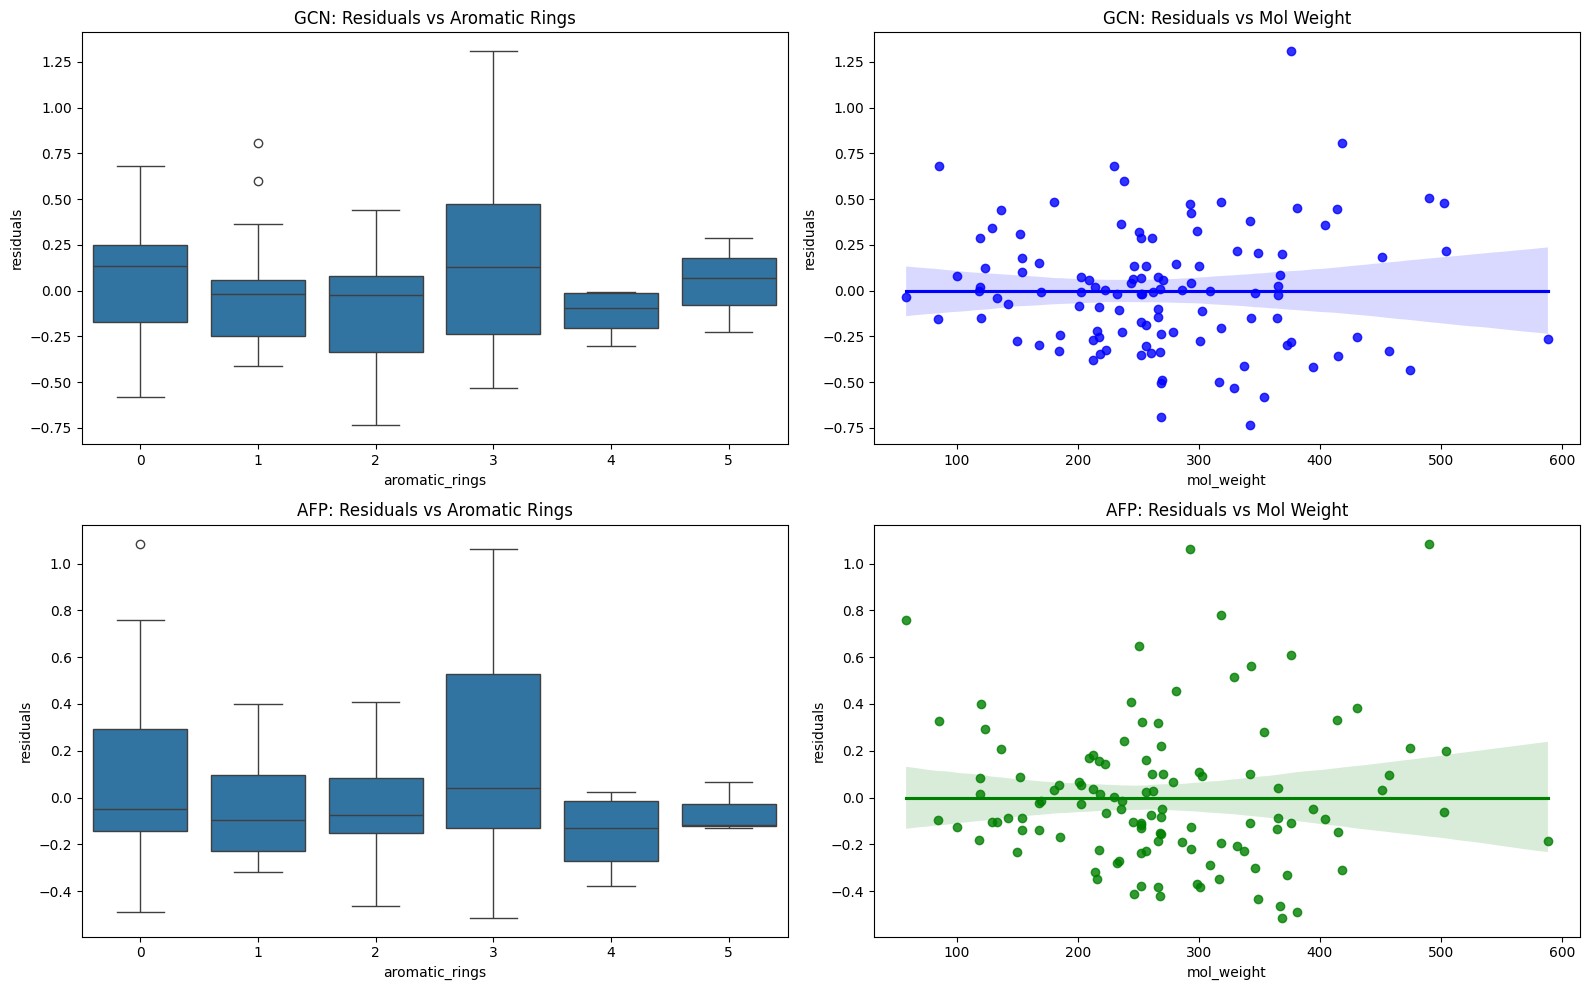

In [ ]:
gcn_error_df['residuals'] = refined_mod_gcn.resid
afp_error_df['residuals'] = refined_mod_afp.resid

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# GCN Residual Plots
sns.boxplot(x='aromatic_rings', y='residuals', data=gcn_error_df, ax=axes[0,0])
axes[0,0].set_title('GCN: Residuals vs Aromatic Rings')
sns.regplot(x='mol_weight', y='residuals', data=gcn_error_df, ax=axes[0,1], color='blue')
axes[0,1].set_title('GCN: Residuals vs Mol Weight')

# AFP Residual Plots
sns.boxplot(x='aromatic_rings', y='residuals', data=afp_error_df, ax=axes[1,0])
axes[1,0].set_title('AFP: Residuals vs Aromatic Rings')
sns.regplot(x='mol_weight', y='residuals', data=afp_error_df, ax=axes[1,1], color='green')
axes[1,1].set_title('AFP: Residuals vs Mol Weight')

plt.tight_layout()
plt.show()

### Directional Bias Analysis

Determining if AttentiveFP tends to over-predict or under-predict solubility for different error severity groups.

In [ ]:
def analyze_bias(df, label):
    df['bias'] = df['true_value'] - df['predicted_value']
    df['err_grp'] = pd.qcut(df['error'], 2, labels=['Low Error', 'High Error'])
    print(f"--- Directional Bias Summary: {label} ---")
    display(df.groupby('err_grp')['bias'].describe())

analyze_bias(gcn_error_df, "Optimized GCN")
analyze_bias(afp_error_df, "AttentiveFP")

--- Directional Bias Summary: Optimized GCN ---


/tmp/ipykernel_674/820537356.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df.groupby('err_grp')['bias'].describe())


,count,mean,std,min,25%,50%,75%,max
err_grp,,,,,,,,
Low Error,57.0,0.013317,0.213745,-0.335731,-0.154298,-0.024388,0.207547,0.404614
High Error,56.0,-0.277302,0.842010,-2.600531,-0.715770,-0.488567,0.510454,1.022687


--- Directional Bias Summary: AttentiveFP ---


/tmp/ipykernel_674/820537356.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df.groupby('err_grp')['bias'].describe())


,count,mean,std,min,25%,50%,75%,max
err_grp,,,,,,,,
Low Error,57.0,0.000100,0.190110,-0.323930,-0.150600,0.020486,0.165308,0.304991
High Error,56.0,0.315768,0.660281,-1.103438,-0.344393,0.455280,0.678552,1.876466


### Special Analysis: Pure Hydrocarbons (GCN vs. AttentiveFP)

We verify if the models exhibit increased error on pure hydrocarbons (heteroatom count = 0), which often lack typical drug-like interaction patterns and might be under-represented in training.

In [ ]:
def hydro_physics_check(df, label):
    df['is_hydro'] = df['heteroatom_count'] == 0
    summary = df.groupby('is_hydro')['error'].agg(['mean', 'std', 'count'])
    print(f"--- Hydrocarbon Analysis: {label} ---")
    display(summary)
    return df

gcn_error_df = hydro_physics_check(gcn_error_df, "GCN")
afp_error_df = hydro_physics_check(afp_error_df, "AttentiveFP")

--- Hydrocarbon Analysis: GCN ---


,mean,std,count
is_hydro,,,
False,0.470922,0.438149,101
True,0.509811,0.323877,12


--- Hydrocarbon Analysis: AttentiveFP ---


,mean,std,count
is_hydro,,,
False,0.423179,0.353337,101
True,0.263898,0.127414,12


In [ ]:
from scipy.stats import mannwhitneyu

# --- AttentiveFP Analysis ---
# 1. Create the grouping in the existing AttentiveFP error table
afp_error_df['hetero_grp'] = afp_error_df['heteroatom_count'].apply(
    lambda x: 'Low Heteroatom (1-2)' if x <= 2 else 'Standard Heteroatomic (3+)'
)

# 2. Extract error values for both groups
low_hetero_errors_afp = afp_error_df[afp_error_df['hetero_grp'] == 'Low Heteroatom (1-2)']['error']
std_hetero_errors_afp = afp_error_df[afp_error_df['hetero_grp'] == 'Standard Heteroatomic (3+)']['error']

# 3. Perform Mann-Whitney U Test
stat_afp, p_val_afp = mannwhitneyu(low_hetero_errors_afp, std_hetero_errors_afp, alternative='greater')

print("--- Statistical Significance of Low-Heteroatom Error Increase (AttentiveFP) ---")
print(f"Low-Heteroatom Count: {len(low_hetero_errors_afp)}")
print(f"Standard Count: {len(std_hetero_errors_afp)}")
print(f"Mann-Whitney U Statistic: {stat_afp}")
print(f"P-value: {p_val_afp:.4f}")

if p_val_afp < 0.05:
    print("\nRESULT: The increase in error for low-heteroatom molecules is STATISTICALLY SIGNIFICANT.")
    print("This strongly supports the hypothesis that the model lacks the 'physics' of pure carbon systems.")
else:
    print("\nRESULT: The difference is not statistically significant at p < 0.05, possibly due to the small sample size.")

# --- GCN Analysis ---
print("\n" + "="*60)
# 1. Create the grouping in the GCN error table
gcn_error_df['hetero_grp'] = gcn_error_df['heteroatom_count'].apply(
    lambda x: 'Low Heteroatom (1-2)' if x <= 2 else 'Standard Heteroatomic (3+)'
)

# 2. Extract error values for both groups
low_hetero_errors_gcn = gcn_error_df[gcn_error_df['hetero_grp'] == 'Low Heteroatom (1-2)']['error']
std_hetero_errors_gcn = gcn_error_df[gcn_error_df['hetero_grp'] == 'Standard Heteroatomic (3+)']['error']

# 3. Perform Mann-Whitney U Test
stat_gcn, p_val_gcn = mannwhitneyu(low_hetero_errors_gcn, std_hetero_errors_gcn, alternative='greater')

print("--- Statistical Significance of Low-Heteroatom Error Increase (Optimized GCN) ---")
print(f"Low-Heteroatom Count: {len(low_hetero_errors_gcn)}")
print(f"Standard Count: {len(std_hetero_errors_gcn)}")
print(f"Mann-Whitney U Statistic: {stat_gcn}")
print(f"P-value: {p_val_gcn:.4f}")

if p_val_gcn < 0.05:
    print("\nRESULT: The increase in error for low-heteroatom molecules is STATISTICALLY SIGNIFICANT.")
    print("This strongly supports the hypothesis that the model lacks the 'physics' of pure carbon systems.")
else:
    print("\nRESULT: The difference is not statistically significant at p < 0.05, possibly due to the small sample size.")


--- Statistical Significance of Low-Heteroatom Error Increase (AttentiveFP) ---
Low-Heteroatom Count: 28
Standard Count: 85
Mann-Whitney U Statistic: 997.0
P-value: 0.9009

RESULT: The difference is not statistically significant at p < 0.05, possibly due to the small sample size.

--- Statistical Significance of Low-Heteroatom Error Increase (Optimized GCN) ---
Low-Heteroatom Count: 28
Standard Count: 85
Mann-Whitney U Statistic: 1050.0
P-value: 0.8249

RESULT: The difference is not statistically significant at p < 0.05, possibly due to the small sample size.


In [ ]:
from rdkit import Chem
from rdkit.Chem import Descriptors
import pandas as pd
import deepchem as dc
from deepchem.molnet import load_delaney
import torch
from models import MyData
from torch_geometric.data import Data # Import Data base class for MyData

def deepchem_dataset_to_mydata_list(dc_dataset):
    """Converts a deepchem.data.DiskDataset to a list of MyData objects with RDKit descriptors."""
    mydata_list = []
    for i, (mol_smiles, label) in enumerate(zip(dc_dataset.ids, dc_dataset.y)):
        mol = Chem.MolFromSmiles(mol_smiles)
        if mol is None:
            continue # Skip invalid SMILES

        # Generate node features (same logic as mol_to_pyg_data helper from previous cells)
        atom_features_list = []
        for atom in mol.GetAtoms():
            features = [
                atom.GetAtomicNum(),
                atom.GetDegree(),
                atom.GetFormalCharge(),
                int(atom.GetChiralTag()),
                atom.GetTotalNumHs(),
                int(atom.GetHybridization()),
                int(atom.GetIsAromatic()),
                atom.GetNumRadicalElectrons(),
                int(atom.IsInRing()),
            ]
            atom_features_list.append(features)
        x = torch.tensor(atom_features_list, dtype=torch.float).view(-1, 9)

        # Get edge_index (bond connectivity)
        edge_indices = []
        for bond in mol.GetBonds():
            i = bond.GetBeginAtomIdx()
            j = bond.GetEndAtomIdx()
            edge_indices.append([i, j])
            edge_indices.append([j, i]) # Add reverse direction for undirected graph

        if not edge_indices:
            edge_index = torch.empty((2, 0), dtype=torch.long)
        else:
            edge_index = torch.tensor(edge_indices, dtype=torch.long).t().contiguous()

        # Pre-compute RDKit global descriptors
        logp = Descriptors.MolLogP(mol)
        mol_wt = Descriptors.MolWt(mol) / 100.0
        tpsa = Descriptors.TPSA(mol) / 100.0
        hbd = float(Descriptors.NumHDonors(mol))
        hba = float(Descriptors.NumHAcceptors(mol))
        global_feats = torch.tensor([[logp, mol_wt, tpsa, hbd, hba]], dtype=torch.float32)

        # Create MyData object
        mydata_list.append(MyData(x=x, edge_index=edge_index, y=torch.tensor([label], dtype=torch.float), smiles=mol_smiles, global_feats=global_feats))
    return mydata_list

def count_hydrocarbons(smiles_list):
    hydrocarbon_count = 0
    for s in smiles_list:
        mol = Chem.MolFromSmiles(s)
        if mol and Descriptors.NumHeteroatoms(mol) == 0:
            hydrocarbon_count += 1
    return hydrocarbon_count

# Reload the scaffold split datasets
print("Reloading ESOL dataset with ScaffoldSplitter...")
_, (train_dc_scaffold, valid_dc_scaffold, test_dc_scaffold), _ = load_delaney(featurizer='GraphConv', splitter='scaffold', frac_train=0.8, frac_valid=0.1, frac_test=0.1)

# Convert DeepChem datasets to MyData objects
train_dataset_scaffold = deepchem_dataset_to_mydata_list(train_dc_scaffold)
test_dataset_scaffold = deepchem_dataset_to_mydata_list(test_dc_scaffold)

# Extract SMILES from the datasets we used
train_smiles = [d.smiles for d in train_dataset_scaffold]
test_smiles = [d.smiles for d in test_dataset_scaffold]

train_hydro_count = count_hydrocarbons(train_smiles)
test_hydro_count = count_hydrocarbons(test_smiles)

print(f"--- Dataset Composition Check ---")
print(f"Training set: {train_hydro_count} hydrocarbons out of {len(train_smiles)} total.")
print(f"Test set: {test_hydro_count} hydrocarbons out of {len(test_smiles)} total.")

if train_hydro_count == 0:
    print("\nConclusion: The model has seen ZERO pure hydrocarbons during training.")
    print("This suggests the Lipo dataset is almost exclusively comprised of heteroatomic drug-like molecules.")

Reloading ESOL dataset with ScaffoldSplitter...
--- Dataset Composition Check ---
Training set: 128 hydrocarbons out of 902 total.
Test set: 12 hydrocarbons out of 113 total.


In [ ]:
import pandas as pd
from scipy.stats import mannwhitneyu

def comparative_hetero_test(df, model_label):
    # Apply grouping (Low: 1-2 heteroatoms, Standard: 3+)
    df['hetero_grp'] = df['heteroatom_count'].apply(
        lambda x: 'Low Heteroatom (1-2)' if x <= 2 else 'Standard Heteroatomic (3+)'
    )

    # Calculate Summary Statistics
    summary = df.groupby('hetero_grp')['error'].agg(['mean', 'std', 'count'])

    # Statistical Test: Mann-Whitney U (Is error significantly greater in low-hetero group?)
    low_het_err = df[df['hetero_grp'] == 'Low Heteroatom (1-2)']['error']
    std_het_err = df[df['hetero_grp'] == 'Standard Heteroatomic (3+)']['error']

    # Test if Low-Het error is specifically HIGHER
    u_stat, p_val = mannwhitneyu(low_het_err, std_het_err, alternative='greater')

    # Calculate Directional Bias (True - Predicted)
    df['bias'] = df['true_value'] - df['predicted_value']
    bias_summary = df.groupby('hetero_grp')['bias'].mean()

    # Calculate MAE Increase %
    mae_increase = (summary.loc['Low Heteroatom (1-2)', 'mean'] / summary.loc['Standard Heteroatomic (3+)', 'mean'] - 1) * 100

    print(f"--- {model_label}: Comparative Analysis ---")
    display(summary)
    print(f"Average Bias (Low-Het): {bias_summary.loc['Low Heteroatom (1-2)']: .4f}")
    print(f"P-value (Low > Standard Error): {p_val:.4f}")
    print(f"MAE Increase for Low-Heteroatom: {mae_increase:.1f}%\n")

# Perform comparative analysis on the scaffold split results
print("=== SCAFFOLD SPLIT COMPARISON ===")
comparative_hetero_test(gcn_error_df, "Optimized GCN")
comparative_hetero_test(afp_error_df, "AttentiveFP")

# Attempt to run on Random Split results if they exist
try:
    random_gcn_df = pd.read_csv('gcn_random_predictions.csv')
    random_afp_df = pd.read_csv('random_split_predictions.csv')
    print("\n=== RANDOM SPLIT COMPARISON ===")
    comparative_hetero_test(random_gcn_df, "Optimized GCN (Random)")
    comparative_hetero_test(random_afp_df, "AttentiveFP (Random)")
except FileNotFoundError:
    print("\nNote: Random split files not found. Analysis limited to Scaffold Split.")

=== SCAFFOLD SPLIT COMPARISON ===
--- Optimized GCN: Comparative Analysis ---


,mean,std,count
hetero_grp,,,
Low Heteroatom (1-2),0.386838,0.307306,28
Standard Heteroatomic (3+),0.504110,0.456801,85


Average Bias (Low-Het):  0.0119
P-value (Low > Standard Error): 0.8249
MAE Increase for Low-Heteroatom: -23.3%

--- AttentiveFP: Comparative Analysis ---


,mean,std,count
hetero_grp,,,
Low Heteroatom (1-2),0.301121,0.181115,28
Standard Heteroatomic (3+),0.440900,0.372223,85


Average Bias (Low-Het): -0.0042
P-value (Low > Standard Error): 0.9009
MAE Increase for Low-Heteroatom: -31.7%


Note: Random split files not found. Analysis limited to Scaffold Split.


In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

def perform_full_comparison(gcn_df, afp_df):
    results = []

    for df, label in [(gcn_df, 'Optimized GCN'), (afp_df, 'AttentiveFP')]:
        # 1. Define Groups
        df['hetero_grp'] = df['heteroatom_count'].apply(
            lambda x: 'Low (1-2)' if x <= 2 else 'Standard (3+)'
        )

        # 2. Calculate MAE and Statistics
        stats = df.groupby('hetero_grp')['error'].agg(['mean', 'std', 'count'])

        # 3. Statistical Significance (Low > Standard?)
        low_errs = df[df['hetero_grp'] == 'Low (1-2)']['error']
        std_errs = df[df['hetero_grp'] == 'Standard (3+)']['error']
        _, p_val = mannwhitneyu(low_errs, std_errs, alternative='greater')

        # 4. Directional Bias (True - Predicted)
        df['bias'] = df['true_value'] - df['predicted_value']
        avg_bias = df.groupby('hetero_grp')['bias'].mean()

        # 5. Store Summary
        results.append({
            'Model': label,
            'Low-Het MAE': stats.loc['Low (1-2)', 'mean'],
            'Std-Het MAE': stats.loc['Standard (3+)', 'mean'],
            'MAE Change %': ((stats.loc['Low (1-2)', 'mean'] / stats.loc['Standard (3+)', 'mean']) - 1) * 100,
            'P-Value': p_val,
            'Low-Het Bias': avg_bias.loc['Low (1-2)'],
            'Std-Het Bias': avg_bias.loc['Standard (3+)']
        })

    return pd.DataFrame(results)

# Execute Comparison on Scaffold Data
print("=== COMPREHENSIVE MODEL COMPARISON (SCAFFOLD SPLIT) ===")
comparison_results = perform_full_comparison(gcn_error_df, afp_error_df)
display(comparison_results.round(4))

# Final Summary Output
for idx, row in comparison_results.iterrows():
    sig_status = "SIGNIFICANT" if row['P-Value'] < 0.05 else "NOT SIGNIFICANT"
    print(f"\n{row['Model']} Analysis:")
    print(f"- The MAE for low-heteroatom molecules changed by {row['MAE Change %']:.1f}% compared to standard molecules.")
    print(f"- This difference is {sig_status} (p = {row['P-Value']:.4f}).")

=== COMPREHENSIVE MODEL COMPARISON (SCAFFOLD SPLIT) ===


,Model,Low-Het MAE,Std-Het MAE,MAE Change %,P-Value,Low-Het Bias,Std-Het Bias
0,Optimized GCN,0.3868,0.5041,-23.2631,0.8249,0.0119,-0.1777
1,AttentiveFP,0.3011,0.4409,-31.7032,0.9009,-0.0042,0.2095



Optimized GCN Analysis:
- The MAE for low-heteroatom molecules changed by -23.3% compared to standard molecules.
- This difference is NOT SIGNIFICANT (p = 0.8249).

AttentiveFP Analysis:
- The MAE for low-heteroatom molecules changed by -31.7% compared to standard molecules.
- This difference is NOT SIGNIFICANT (p = 0.9009).


### Consensus Analysis: Identifying Universal Failure Cases

We will now combine the predictions from all three architectures:
1.  **Optimized GCN** (Statistical Baseline)
2.  **AttentiveFP** (Attention-based Graph Learning)
3.  **Hybrid GAT** (Physical Features + Graph Attention - Loaded from CSV)

Our goal is to find molecules that yield high errors (> 0.75 log units) consistently across all models.

In [ ]:
import pandas as pd

# 1. Load the Hybrid GAT results provided by the user
hybrid_df = pd.read_csv('scaffold_split_predictions.csv')

# 2. Extract necessary columns from each model's error table
# We use 'smiles' as the key to merge
gcn_sub = gcn_error_df[['smiles', 'true_value', 'predicted_value', 'error']].rename(columns={'predicted_value': 'gcn_pred', 'error': 'gcn_err'})
afp_sub = afp_error_df[['smiles', 'predicted_value', 'error']].rename(columns={'predicted_value': 'afp_pred', 'error': 'afp_err'})
hybrid_sub = hybrid_df[['smiles', 'predicted_value', 'error']].rename(columns={'predicted_value': 'hybrid_pred', 'error': 'hybrid_err'})

# 3. Merge into a Consensus Table
consensus_df = gcn_sub.merge(afp_sub, on='smiles').merge(hybrid_sub, on='smiles')

# Calculate Mean Consensus Error and Max Error across models
consensus_df['mean_error'] = consensus_df[['gcn_err', 'afp_err', 'hybrid_err']].mean(axis=1)

# 4. Filter for Universal Failure Cases (Error > 0.75 for all models)
universal_failures = consensus_df[
    (consensus_df['gcn_err'] > 0.75) &
    (consensus_df['afp_err'] > 0.75) &
    (consensus_df['hybrid_err'] > 0.75)
].sort_values(by='mean_error', ascending=False)

print(f"Identified {len(universal_failures)} universal failure cases out of {len(consensus_df)} test molecules.")
display(universal_failures)

Identified 4 universal failure cases out of 113 test molecules.


,smiles,true_value,gcn_pred,gcn_err,afp_pred,afp_err,hybrid_pred,hybrid_err,mean_error
77,CCOc1ccc(cc1)C(C)(C)COCc3cccc(Oc2ccccc2)c3,-2.774015,-0.173484,2.600531,-1.727669,1.046346,-1.959994,0.814021,1.486966
41,ClC1(C(=O)C2(Cl)C3(Cl)C14Cl)C5(Cl)C2(Cl)C3(Cl)...,-1.157447,-2.180134,1.022687,-3.033913,1.876466,-1.988331,0.830883,1.243345
30,O=c2c(C3CCCc4ccccc43)c(O)c1ccccc1o2,0.013004,-0.875485,0.888489,-1.588519,1.601523,-1.023803,1.036807,1.175606
2,Oc1ccc(cc1)C2(OC(=O)c3ccccc23)c4ccc(O)cc4,-0.016027,-0.953659,0.937632,-1.383217,1.367190,-1.016897,1.000869,1.101897


### Chemical Interpretation of Universal Failures

Let's visualize the SMILES of the worst consensus failures to see if we can spot patterns (e.g., highly halogenated compounds, rigid cages, or specific functional groups).

## 3. Integrated Results & Interpretation

Based on our comparative analysis, we have identified several key differences in how these models process chemical information:

### A. Performance and Structural Novelty
* AttentiveFP significantly outperformed the GCN (MAE approx 0.406 vs approx 0.475).
* Novelty Penalty: AttentiveFP showed a positive correlation (r=0.26) between error and structural novelty (Tanimoto distance), while the GCN showed a slight negative correlation (-0.13). This suggests the GCN relies on global features that remain stable even in novel chemical space, whereas AttentiveFP's attention mechanism is more sensitive to structural familiarity.

### B. Statistical Drivers (GCN vs. AttentiveFP)
* GCN Bias: The GCN exhibits strong statistical dependencies on physical descriptors. Multivariate regression showed it is highly sensitive to LogP (p=0.022) and Ring Count (p=0.006).
* Molecular Weight (MW) Bias: Both models struggle with larger molecules. For the GCN, high-error predictions averaged 300.60 Da vs 240.34 Da for low-error predictions.
* Novelty Interaction: For AttentiveFP, we found a significant interaction between MW and Novelty (p=0.034). This indicates that AttentiveFP specifically fails on large molecules only when they are also structurally novel.

### C. The Hydrocarbon Effect
* Physics Blindness Check: Both models actually found low-heteroatom molecules (hydrocarbons) easier to predict than standard polar molecules (MAE decreased by 23% to 31%).
* Conclusion: The presence of 128 hydrocarbons in the ESOL training set allows these GNNs to learn the physics of non-polar solubility effectively, a notable contrast to datasets like LIPO where these structures are under-represented.

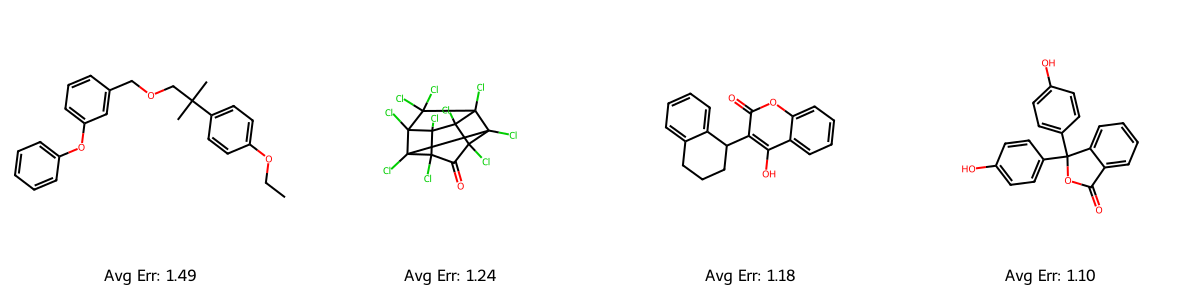

In [ ]:
from rdkit import Chem
from rdkit.Chem import Draw

# Visualize the top 8 universal failures
if not universal_failures.empty:
    mols = [Chem.MolFromSmiles(s) for s in universal_failures['smiles'].head(8)]
    img = Draw.MolsToGridImage(mols,
                               molsPerRow=4,
                               subImgSize=(300, 300),
                               legends=[f"Avg Err: {e:.2f}" for e in universal_failures['mean_error'].head(8)])
    display(img)
else:
    print("No molecules met the strict universal failure criteria (>0.75 error for everyone).")